# Class Quiz

### Guideline

1. Please submit the file via Google Classroom.
2. File name convention is MSA38DN\_\<Your full name\>\_classquizN
3. Provide your personal information in the next block.


### Student information

Full name: Bùi Ngọc Bảo Trân

Student ID: 25MS33062

Group: 2


In [ ]:
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

import requests

# define your addition imported libraries below

In [ ]:
def download_input_data(url):
    print(f"Downloading from {url}")
    # Download the image.
    response = requests.get(url, stream=True)
    response.raise_for_status()

    # Read the image data from the response
    image_data = np.asarray(bytearray(response.content), dtype="uint8")

    # Decode the image using OpenCV
    img_gray = cv.imdecode(image_data, cv.IMREAD_COLOR_RGB)

    return img_gray

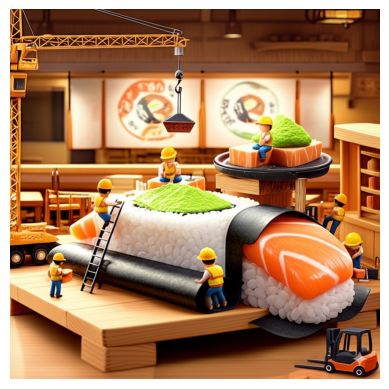

In [ ]:
file_id = "1WRLpWrhsJgguvdAdFNcdGZdc_3NrTmjq"
download_url = f"https://drive.google.com/uc?export=download&id={file_id}"
img_gray = download_input_data(download_url)

plt.imshow(img_gray, cmap="gray")
plt.axis("off")
plt.show()

# Requirements

1. Display the R,G, and B-channels of the input image as three different images.
2. Extract the lightness data from the input image and display it as a grayscale image.
3. Perform edge detection on the given image by spatial and frequency approaches (one for each). Display the results.
4. Thicken the edges and remove trivial details from the output (3). Display the results.
5. Switch all yellow areas in the input image to blue.
6. Redo (3) and (4) with the output image (5). Comment the differences.


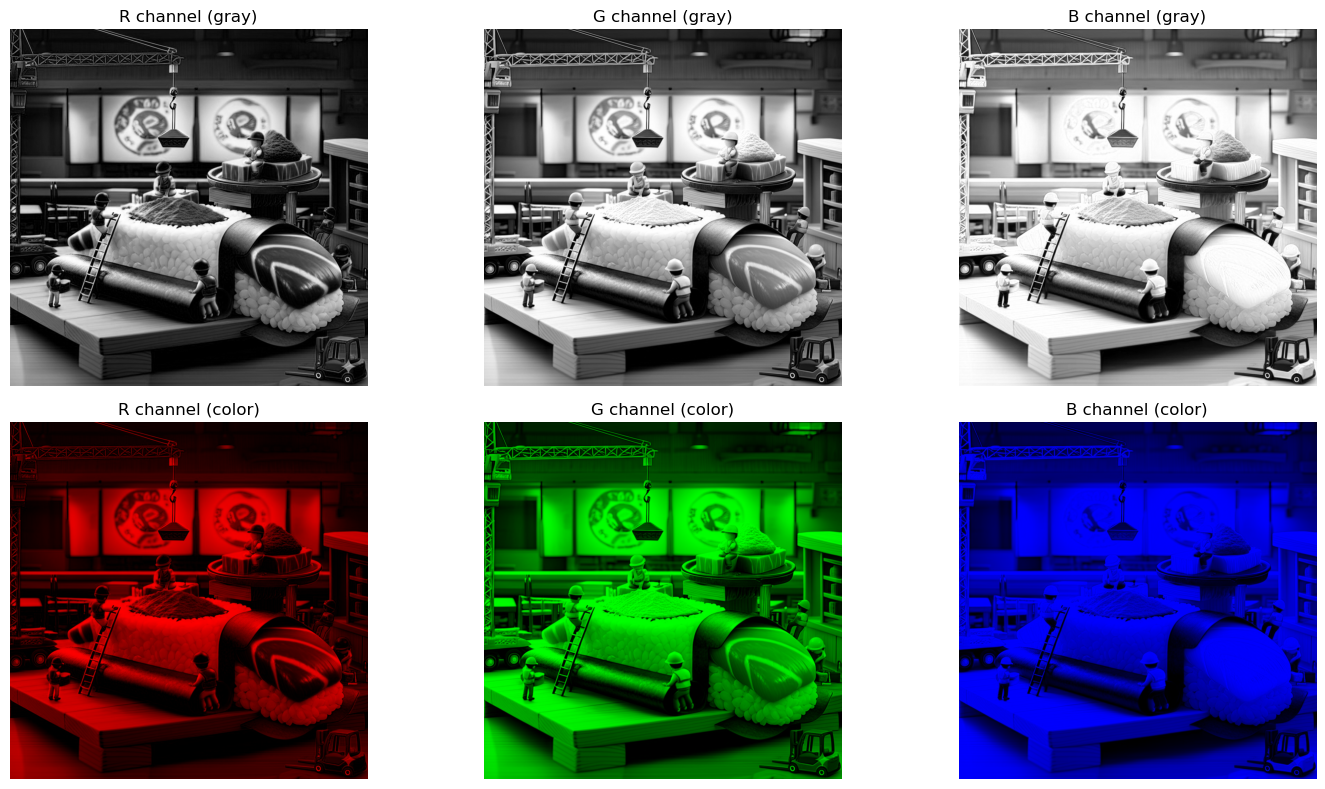

In [ ]:
# 1. Display the R,G, and B-channels of the input image as three different images.
img_rgb = cv.cvtColor(img_gray, cv.COLOR_BGR2RGB)

R = img_rgb[:, :, 0]
G = img_rgb[:, :, 1]
B = img_rgb[:, :, 2]

R_img = np.zeros_like(img_rgb)
G_img = np.zeros_like(img_rgb)
B_img = np.zeros_like(img_rgb)

R_img[:, :, 0] = R
G_img[:, :, 1] = G
B_img[:, :, 2] = B

plt.figure(figsize=(15, 8))

# Display results
plt.subplot(2, 3, 1)
plt.imshow(R, cmap="gray")
plt.title("R channel (gray)")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(G, cmap="gray")
plt.title("G channel (gray)")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(B, cmap="gray")
plt.title("B channel (gray)")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(R_img)
plt.title("R channel (color)")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(G_img)
plt.title("G channel (color)")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(B_img)
plt.title("B channel (color)")
plt.axis("off")

plt.tight_layout()
plt.show()

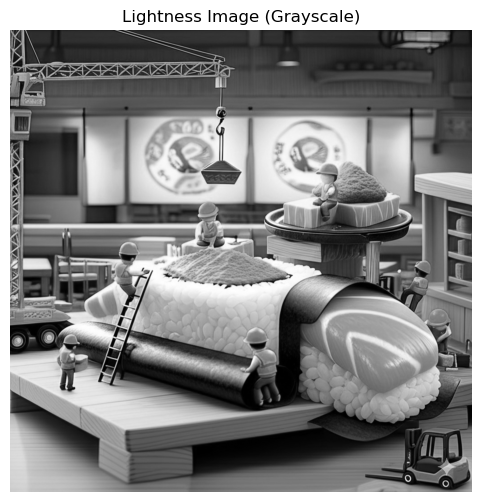

In [ ]:
# 2. Extract the lightness data from the input image and display it as a grayscale image.
img_rgb = cv.cvtColor(img_gray, cv.COLOR_BGR2RGB)

R = img_rgb[:, :, 0].astype(np.float32)
G = img_rgb[:, :, 1].astype(np.float32)
B = img_rgb[:, :, 2].astype(np.float32)

lightness = (np.maximum.reduce([R, G, B]) + np.minimum.reduce([R, G, B])) / 2

lightness = np.clip(lightness, 0, 255).astype(np.uint8)

# Display results
plt.figure(figsize=(6, 6))
plt.imshow(lightness, cmap="gray")
plt.title("Lightness Image (Grayscale)")
plt.axis("off")
plt.show()

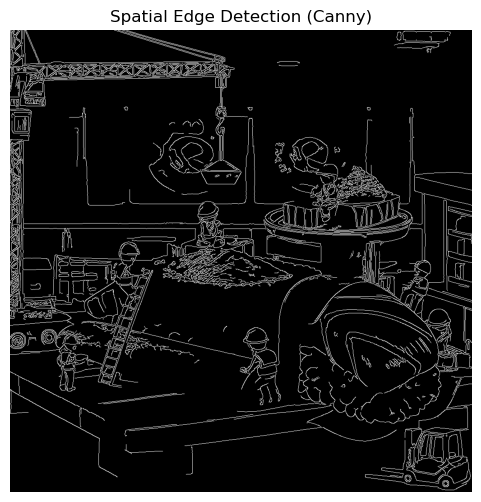

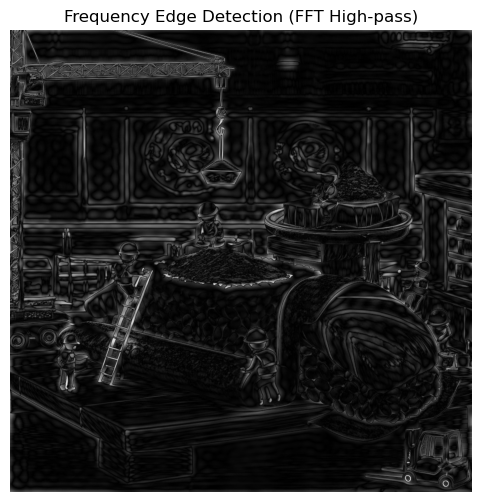

In [ ]:
# 3. Perform edge detection on the given image by spatial and frequency approaches (one for each). Display the results.
img_rgb = cv.cvtColor(img_gray, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img_rgb, cv.COLOR_RGB2GRAY)

edges_spatial = cv.Canny(gray, 100, 200)

plt.figure(figsize=(6, 6))
plt.imshow(edges_spatial, cmap="gray")
plt.title("Spatial Edge Detection (Canny)")
plt.axis("off")
plt.show()

f = np.fft.fft2(gray)
fshift = np.fft.fftshift(f)

rows, cols = gray.shape
crow, ccol = rows // 2, cols // 2

mask = np.ones((rows, cols), np.uint8)
r = 30
mask[crow - r : crow + r, ccol - r : ccol + r] = 0

fshift_filtered = fshift * mask

img_back = np.fft.ifft2(np.fft.ifftshift(fshift_filtered))
img_back = np.abs(img_back)

img_back = cv.normalize(img_back, None, 0, 255, cv.NORM_MINMAX)
img_back = img_back.astype(np.uint8)

# Display results
plt.figure(figsize=(6, 6))
plt.imshow(img_back, cmap="gray")
plt.title("Frequency Edge Detection (FFT High-pass)")
plt.axis("off")
plt.show()

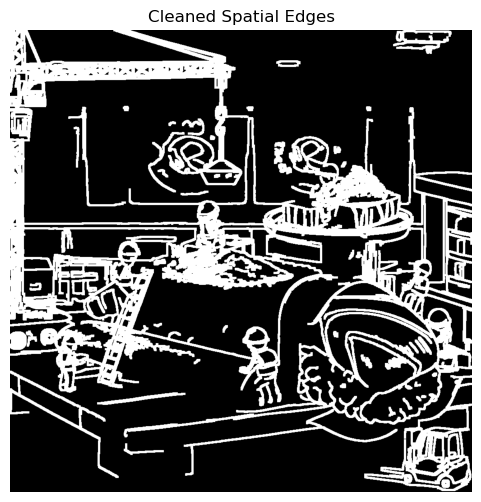

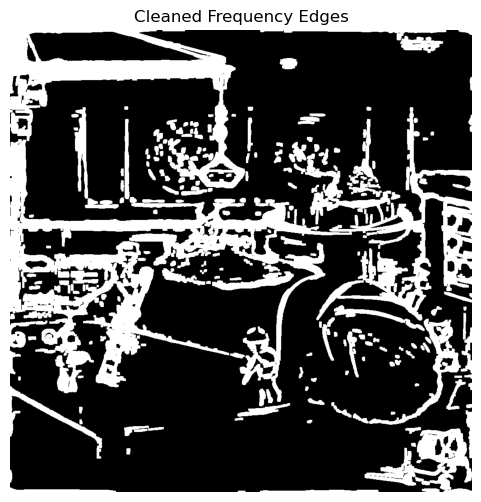

In [ ]:
# 4. Thicken the edges and remove trivial details from the output (3). Display the results.
kernel = np.ones((3, 3), np.uint8)

# 1. SPATIAL EDGE PROCESSING
thick_spatial = cv.dilate(edges_spatial, kernel, iterations=2)

num_labels, labels, stats, _ = cv.connectedComponentsWithStats(
    thick_spatial, connectivity=8
)

clean_spatial = np.zeros_like(thick_spatial)

for i in range(1, num_labels):
    area = stats[i, cv.CC_STAT_AREA]
    if area > 50:  # noise threshold
        clean_spatial[labels == i] = 255

# Display spatial result
plt.figure(figsize=(6, 6))
plt.imshow(clean_spatial, cmap="gray")
plt.title("Cleaned Spatial Edges")
plt.axis("off")
plt.show()

# 2. FREQUENCY EDGE PROCESSING
_, freq_binary = cv.threshold(img_back, 50, 255, cv.THRESH_BINARY)

thick_freq = cv.dilate(freq_binary, kernel, iterations=2)

num_labels, labels, stats, _ = cv.connectedComponentsWithStats(
    thick_freq, connectivity=8
)

clean_freq = np.zeros_like(thick_freq)

for i in range(1, num_labels):
    area = stats[i, cv.CC_STAT_AREA]
    if area > 50:
        clean_freq[labels == i] = 255

# Display results
plt.figure(figsize=(6, 6))
plt.imshow(clean_freq, cmap="gray")
plt.title("Cleaned Frequency Edges")
plt.axis("off")
plt.show()

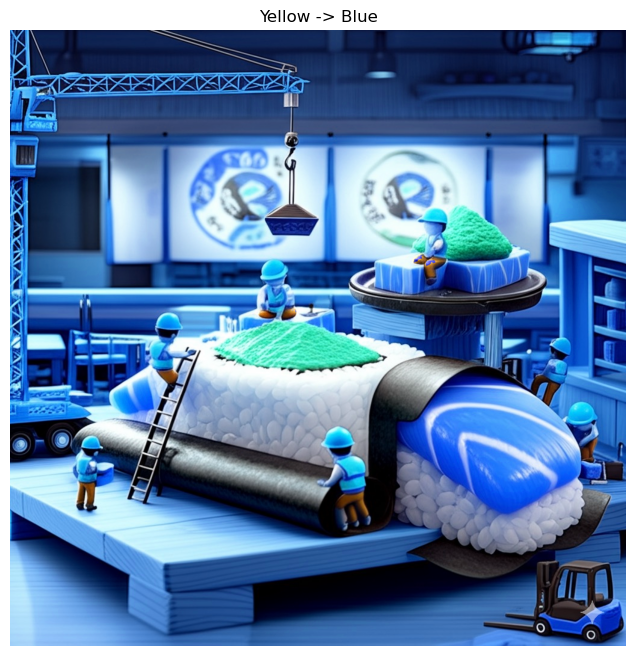

In [ ]:
# 5. Switch all yellow areas in the input image to blue.
hsv = cv.cvtColor(img_rgb, cv.COLOR_RGB2HSV)

lower_yellow = np.array([20, 80, 80])
upper_yellow = np.array([40, 255, 255])

yellow_mask = cv.inRange(hsv, lower_yellow, upper_yellow)

result_hsv = hsv.copy()

result_hsv[:, :, 0][yellow_mask > 0] = 120

img_blue = cv.cvtColor(result_hsv, cv.COLOR_HSV2RGB)

# Display results
plt.figure(figsize=(8, 8))
plt.imshow(img_blue)
plt.title("Yellow -> Blue")
plt.axis("off")
plt.show()

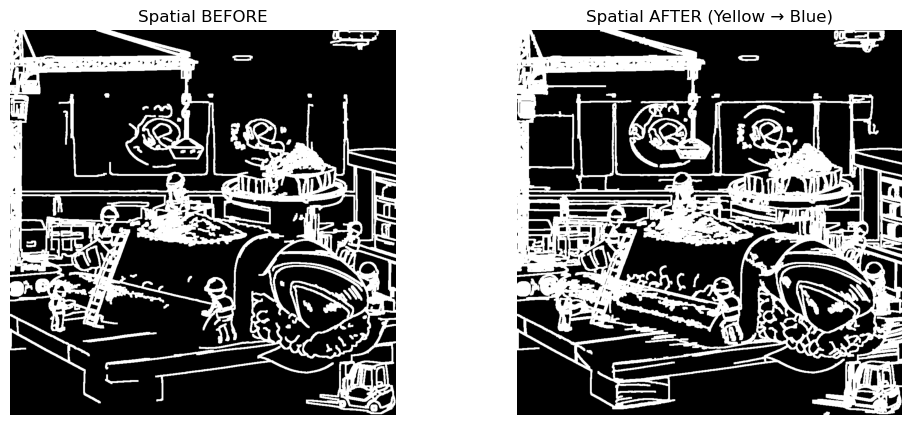

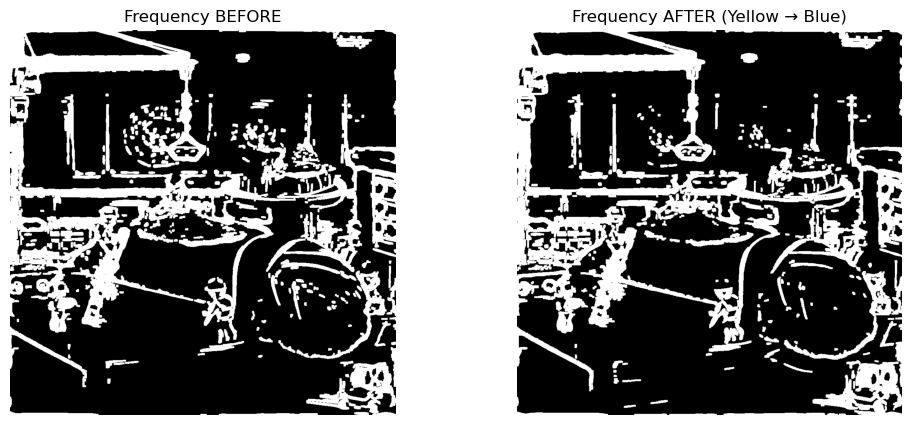

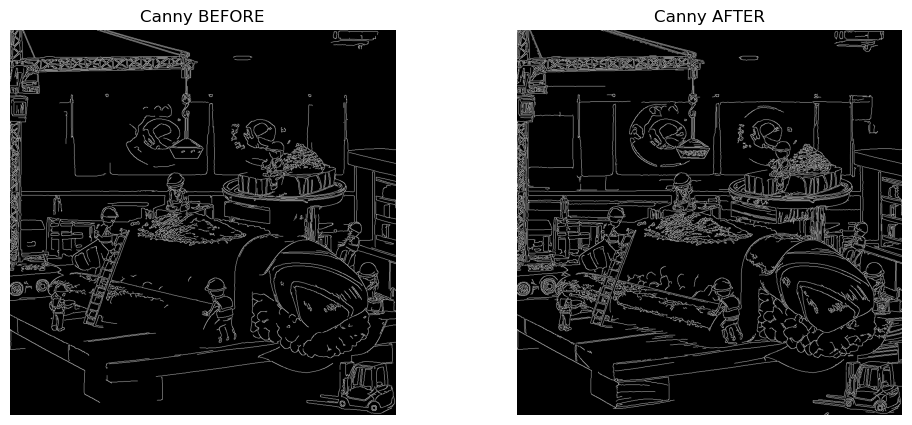

In [ ]:
# 6. Redo (3) and (4) with the output image (5). Comment the differences.
gray2 = (
    0.299 * img_blue[:, :, 0] + 0.587 * img_blue[:, :, 1] + 0.114 * img_blue[:, :, 2]
).astype(np.uint8)

gray2 = cv.equalizeHist(gray2)

# SPATIAL EDGE (Canny)
edges_spatial2 = cv.Canny(gray2, 50, 150)

# FREQUENCY EDGE (FFT High-pass)
f = np.fft.fft2(gray2)
fshift = np.fft.fftshift(f)

rows, cols = gray2.shape
crow, ccol = rows // 2, cols // 2

mask = np.ones((rows, cols), np.uint8)
r = 30
mask[crow - r : crow + r, ccol - r : ccol + r] = 0

fshift_filtered = fshift * mask

img_back2 = np.fft.ifft2(np.fft.ifftshift(fshift_filtered))
img_back2 = np.abs(img_back2)

img_back2 = cv.normalize(img_back2, None, 0, 255, cv.NORM_MINMAX)
img_back2 = np.clip(img_back2, 0, 255).astype(np.uint8)

# SPATIAL
kernel = np.ones((3, 3), np.uint8)

thick_spatial2 = cv.dilate(edges_spatial2, kernel, iterations=2)

num_labels, labels, stats, _ = cv.connectedComponentsWithStats(
    thick_spatial2, connectivity=8
)

clean_spatial2 = np.zeros_like(thick_spatial2)

for i in range(1, num_labels):
    if stats[i, cv.CC_STAT_AREA] > 50:
        clean_spatial2[labels == i] = 255

# FREQUENCY
_, freq_binary2 = cv.threshold(img_back2, 50, 255, cv.THRESH_BINARY)

thick_freq2 = cv.dilate(freq_binary2, kernel, iterations=2)

num_labels, labels, stats, _ = cv.connectedComponentsWithStats(
    thick_freq2, connectivity=8
)

clean_freq2 = np.zeros_like(thick_freq2)

for i in range(1, num_labels):
    if stats[i, cv.CC_STAT_AREA] > 50:
        clean_freq2[labels == i] = 255

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(clean_spatial, cmap="gray")
plt.title("Spatial BEFORE")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(clean_spatial2, cmap="gray")
plt.title("Spatial AFTER (Yellow → Blue)")
plt.axis("off")

plt.show()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(clean_freq, cmap="gray")
plt.title("Frequency BEFORE")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(clean_freq2, cmap="gray")
plt.title("Frequency AFTER (Yellow → Blue)")
plt.axis("off")

plt.show()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(edges_spatial, cmap="gray")
plt.title("Canny BEFORE")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges_spatial2, cmap="gray")
plt.title("Canny AFTER")
plt.axis("off")

plt.show()

### The differents:

#### 1. Spatial Edge Comparison (Canny):

After color transformation, the spatial edge maps remain almost identical, indicating that object boundaries are preserved.
Minor variations may appear due to slight changes in grayscale intensity after replacing yellow with blue.

#### 2. Frequency Edge Comparison (FFT):

The frequency-based edge results show very similar structures before and after transformation, confirming that high-frequency components are unaffected by color changes.
Any small differences come from intensity redistribution in the transformed image.

#### 3. Raw Edge Comparison (Canny visualization):

The raw Canny outputs before and after are nearly the same, demonstrating that edge detection is stable under color modifications.
This confirms that Canny relies on intensity gradients rather than chromatic information.